<a href="https://colab.research.google.com/github/Angela-Benedict/ds2002-fa26/blob/main/notebooks/walmart-hurricane-project/2026-10-30%20%E2%80%94%20Midterm%20Progress%20%E2%80%94%20Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Midterm Progress

**Lab — 2026-10-30 · Fall 2026**  

---

## Lab 10 — Midterm progress, week 2 of 3

One submission per team. Questions 1 through 3 should be substantially answered by now — not polished, but answered, with a number and a chart each.

Presentations are Monday. If a question is not working, this is the last checkpoint where there is time to do something about it, so report the actual state rather than the intended one.

### Q1 — Demand surge

**TODO:** your baseline window, your surge window, the average for each, and the multiple. Plus the chart. State the window boundaries explicitly — a multiple without a window is not a finding.

In [1]:
#cleaned data:
import pandas as pd

!git clone https://github.com/Angela-Benedict/ds2002-fa26.git

sales = pd.read_csv(
    "ds2002-fa26/notebooks/walmart-hurricane-project/data/walmart_transactions.csv"
)
q1 = sales.copy()

q1["timestamp"] = pd.to_datetime(q1["timestamp"], errors="coerce")
q1["date"] = q1["timestamp"].dt.normalize()
q1["quantity"] = pd.to_numeric(q1["quantity"], errors= "coerce")

q1['category_clean'] = (
    q1["category"]
    .astype(str)
    .str.strip()
    .str.lower()
)

category_map = {
    "emergency": "Emergency Supplies",
    'emergency supplies': "Emergency Supplies",
    "groceries": "Groceries",
    "grocery": "Groceries",
    "electronics": "Electronics",
    "household": "Household",
    "household essentials": "Household",
    "baby": "Baby Products",
    "baby products": "Baby Products",
    "breakfast": "Breakfast Foods",
    "breakfast foods":"Breakfast Foods",
    "health":"Health",
    "health & wellness":"Health",
    "alcohol":"Alcohol",
    "alcoholic beverages":"Alcohol",
    'games & entertainment':"Entertainment",
    "entertainment":"Entertainment",
    "snacks":"Snacks"
}
q1["category_clean"] = q1["category_clean"].map(category_map)

daily_category = (
    q1.groupby(["date", "category_clean"]) ["quantity"]
    .sum()
    .reset_index()
)

fatal: destination path 'ds2002-fa26' already exists and is not an empty directory.


In [2]:
#The numbers:
landfall = pd.Timestamp("2024-9-26")

baseline = daily_category[
    (daily_category["date"] >= "2024-9-08") &
    (daily_category["date"] <= "2024-9-15")
]
surge = daily_category[
    (daily_category["date"] >= "2024-9-19") &
    (daily_category["date"] <= "2024-9-25")
]

baseline_avg = baseline.groupby("category_clean")["quantity"].mean()
surge_avg = surge.groupby("category_clean")["quantity"].mean()
surge_multiple = surge_avg / baseline_avg

percent_increase = (surge_multiple - 1) * 100

q1_results = pd.DataFrame({
    "baseline_avg": baseline_avg,
    "pre_landfall_avg": surge_avg,
    "surge_multiple": surge_multiple,
    "percent_increase": percent_increase
}).sort_values("percent_increase", ascending=False)

daily_wide=daily_category.pivot(
    index='date',
    columns='category_clean',
    values = 'quantity'
)

q1_results.round(2)

,baseline_avg,pre_landfall_avg,surge_multiple,percent_increase
category_clean,,,,
Breakfast Foods,9.25,41.00,4.43,343.24
Alcohol,4.57,19.83,4.34,333.85
Emergency Supplies,34.12,101.43,2.97,197.23
Electronics,6.88,17.29,2.51,151.43
Health,4.14,10.00,2.41,141.38
Groceries,17.50,36.29,2.07,107.35
Entertainment,11.00,21.86,1.99,98.70
Household,8.88,17.14,1.93,93.16
Baby Products,7.25,12.57,1.73,73.40


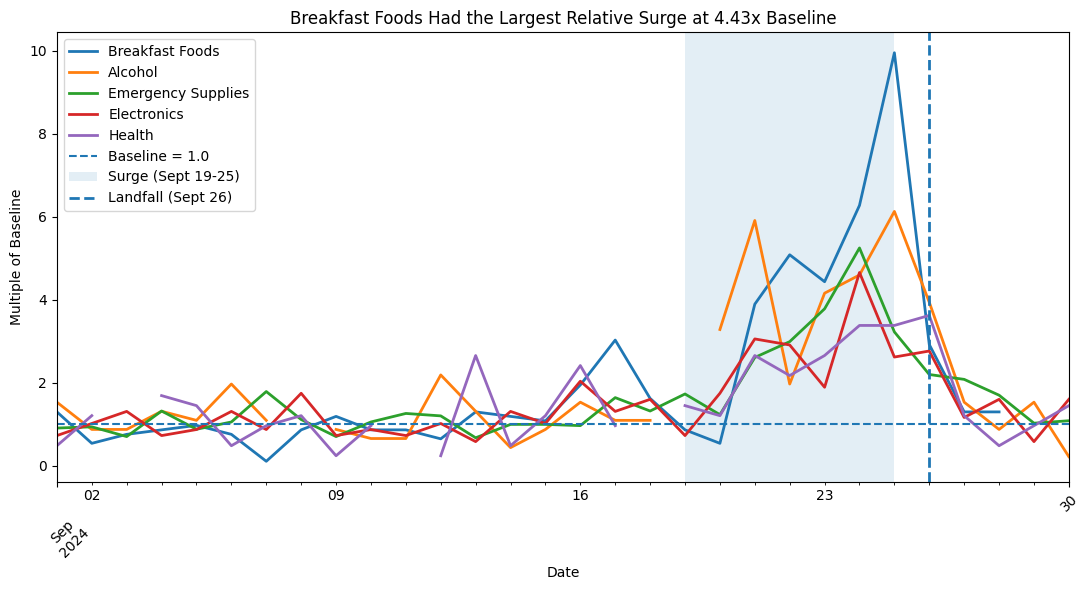

                    surge_multiple  percent_increase
category_clean                                      
Breakfast Foods               4.43            343.24
Alcohol                       4.34            333.85
Emergency Supplies            2.97            197.23
Electronics                   2.51            151.43
Health                        2.41            141.38


In [3]:
#The table:
import matplotlib.pyplot as plt

top5 = q1_results.head(5).index.tolist()

indexed_q1 = daily_wide[top5].div(baseline_avg[top5])

ax = indexed_q1.plot(figsize=(11, 6), linewidth=2)

ax.axhline(1.0, linestyle="--", linewidth=1.5, label="Baseline = 1.0")

ax.axvspan(
    surge["date"].min(),
    surge["date"].max(),
    alpha=0.12,
    label="Surge (Sept 19-25)"
)

ax.axvline(
    pd.Timestamp("2024-09-26"),
    linestyle="--",
    linewidth=2,
    label="Landfall (Sept 26)"
)

ax.set_title("Breakfast Foods Had the Largest Relative Surge at 4.43x Baseline")
ax.set_xlabel("Date")
ax.set_ylabel("Multiple of Baseline")
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

baseline_avg = baseline.mean(numeric_only=True)
surge_avg = surge.mean(numeric_only=True)
surge_multiple = surge_avg / baseline_avg

percent_increase = (surge_multiple - 1) * 100

print(q1_results[["surge_multiple", "percent_increase"]].head(5).round(2))

**Q1 answer, in one sentence a manager could read:** Breakfast Foods experienced the greatest sales surge in the 7 days before hurricane landfall compared to prior baseline, with a 343% increase in sales and a surge multiple of 4.43.

### Q2 — SKU consolidation

**TODO:** how many distinct SKUs you started with, how many canonical products you ended with, your largest consolidated family, and a before-and-after comparison showing what changes. Include the assertion proving consolidation did not change unit totals.

In [4]:
# TODO

**Q2 answer:** _..._

### Q3 — Weather correlation

**TODO:** the API call, the validated join, and the relationship you found. Include:

- the row count before and after the join, proving nothing was lost
- whether the data is live or fallback
- how many days the correlation is computed over

If your n is small, say so here rather than being asked about it on Monday.

In [5]:
# TODO
import pandas as pd, numpy as np, requests, time

# Daily orders from the real transactions file, Sept 8-28, 2024. Note: these are timestamps, not dates.
# (A daily total has no clock time, so we added one. That is what makes this a realistic mess.)
days = pd.date_range('2024-09-08', '2024-09-28')
clock = ['08:14', '09:02', '10:41', '08:33', '11:20', '07:55', '09:10',
         '12:02', '08:44', '10:15', '11:30', '08:05', '11:45', '09:22',
         '10:08', '07:48', '12:30', '09:37', '08:52', '10:26', '11:02']
sales = pd.DataFrame({
    'ts': pd.to_datetime([f'{d:%Y-%m-%d} {c}' for d, c in zip(days, clock)]),
    'orders': [590, 586, 577, 590, 587, 580, 586,
               566, 809, 767, 798, 783, 760, 1313,
               1367, 1374, 1968, 2007, 1139, 851, 879],
})
LANDFALL = pd.Timestamp('2024-09-26')
sales.head()

sales['date'] = sales['ts'].dt.normalize()

fixed = sales.merge(tiny, on='date', how='inner')
print('rows matched:', len(fixed))
fixed[['date', 'orders', 'rain_mm']]

api_shape['date'] = pd.to_datetime(api_shape['time'])
api_shape = api_shape.drop(columns='time')

print('api date dtype:  ', api_shape['date'].dtype)
print('sales date dtype:', sales['date'].dtype)
print('rows matched:    ', len(sales.merge(api_shape, on='date', how='inner')))

NameError: name 'tiny' is not defined

**Q3 answer, with its caveat:** _..._

### Q4 and Q5 — where they stand

**TODO:** one honest sentence each on the remaining two questions and who is finishing them this weekend.

**Q4 (stores and geography):** _..._

**Q5 (signal or artifact):** _..._

### Self-check

In [ ]:
progress = {
    'q1_multiple': None,            # TODO: a number
    'q1_baseline_window': 'TODO',   # TODO: stated explicitly
    'q2_canonical_products': None,  # TODO: a number
    'q3_join_rows_preserved': None, # TODO: True/False
    'q3_days_in_correlation': None, # TODO: a number
    'charts_with_message_titles': None,  # TODO: how many
    'notebook_runs_clean': False,   # TODO: True after Restart and Run All
    'repo_pushed': False,           # TODO
}

for label, value in progress.items():
    filled = not (value is None or value is False
                  or (isinstance(value, str) and value.startswith('TODO')))
    print('PASS' if filled else 'FAIL', '-', label, '=', value)
print()
print('ready for presentations:', all(
    not (v is None or v is False or (isinstance(v, str) and v.startswith('TODO')))
    for v in progress.values()))

### Write-up

**a)** One finding that surprised your team, and what you checked to make sure it was real rather than a bug.

**b)** One number you reported that you are least confident in, and why.

_your answer here_